In [1]:
from google.colab import files
files.upload()

Output hidden; open in https://colab.research.google.com to view.

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact, Dropdown, IntSlider
import plotly.express as px

In [37]:
df = pd.read_excel('/content/USSuperstore.xls')

In [39]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [40]:
df.info()
df.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   datetime64[ns]
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   object        
 8   Country        9994 non-null   object        
 9   City           9994 non-null   object        
 10  State          9994 non-null   object        
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   object        
 13  Product ID     9994 non-null   object        
 14  Category       9994 non-null   object        
 15  Sub-Category   9994 n

(9994, 21)

In [41]:
df.isnull().sum()

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


In [42]:
df.duplicated().sum()

np.int64(0)

In [43]:
df['Order Year'] = df['Order Date'].dt.year
yearly_sales = df.groupby(['Order Year', 'Category'])['Sales'].sum().reset_index()
total_yearly_sales = yearly_sales.groupby('Order Year')['Sales'].sum().reset_index()

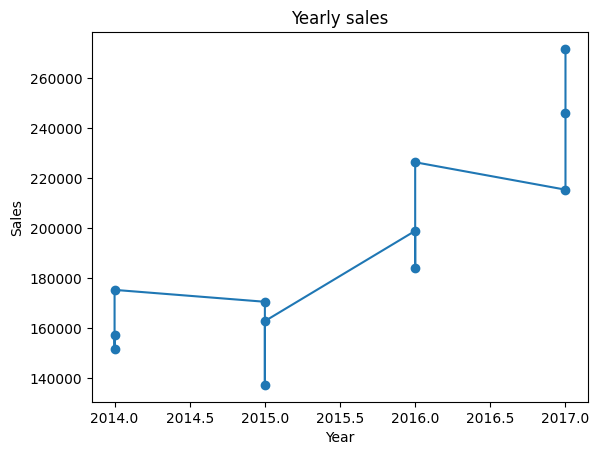

In [44]:
plt.plot(yearly_sales['Order Year'],yearly_sales['Sales'], marker= 'o')
plt.xlabel('Year')
plt.ylabel('Sales')
plt.title('Yearly sales')
plt.show()

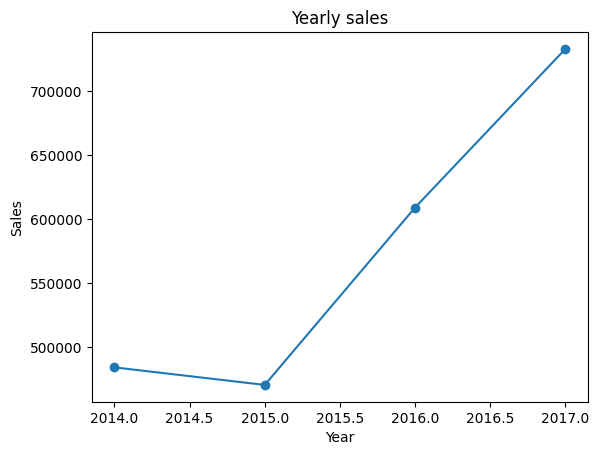

In [45]:
plt.plot(total_yearly_sales['Order Year'],total_yearly_sales['Sales'], marker= 'o')
plt.xlabel('Year')
plt.ylabel('Sales')
plt.title('Yearly sales')
plt.show()

In [46]:
df['Country'].unique()

array(['United States'], dtype=object)

In [47]:
state_sales = df.groupby('State')['Sales'].sum().reset_index()

In [48]:
!pip install us

In [49]:
import us
state_sales['State Code'] = state_sales['State'].apply(
    lambda x: us.states.lookup(x).abbr
)
fig = px.choropleth(
    data_frame= state_sales,
    locations='State Code',
    locationmode='USA-states',
    color= 'Sales',
    scope='usa',
    hover_name = 'State',
    title='Sales Distribution by State'
)

fig.show()

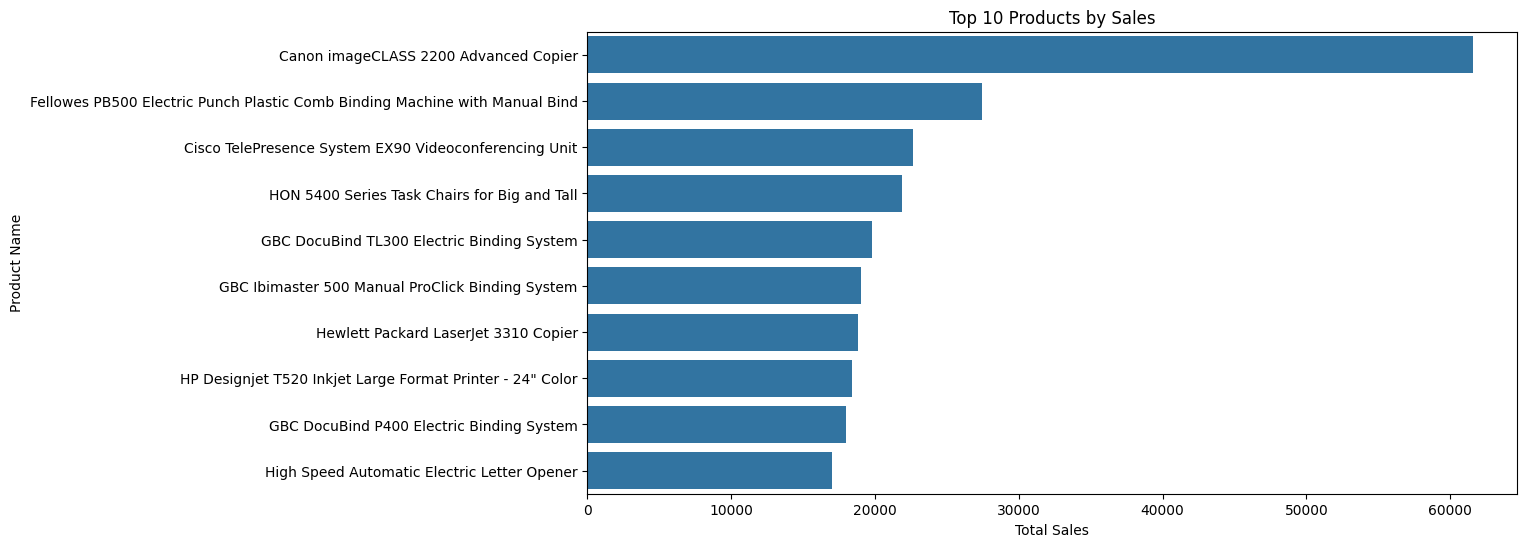

In [50]:
top_products = df.groupby('Product Name')['Sales'].sum().nlargest(10).reset_index()


plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_products,
    x='Sales',
    y='Product Name'
)

plt.title('Top 10 Products by Sales')
plt.xlabel('Total Sales')
plt.ylabel('Product Name')
plt.show()

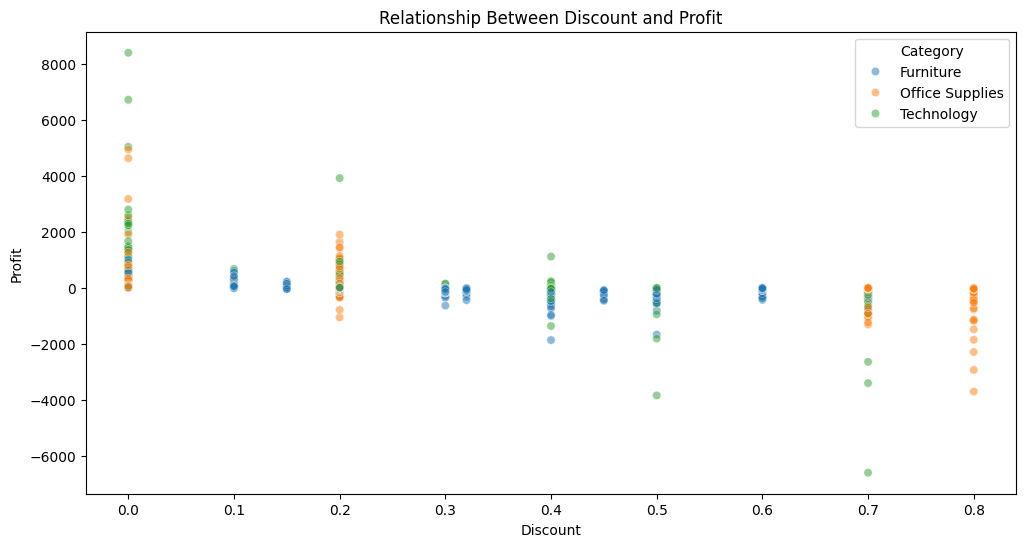

In [52]:
plt.figure(figsize=(12,6))

sns.scatterplot(
    data=df,
    x='Discount',
    y='Profit',
    hue='Category',
    alpha= 0.5
)
plt.title('Relationship Between Discount and Profit')
plt.xlabel('Discount')
plt.ylabel('Profit')
plt.show()

I didn't notice a significant difference between Matplotlib and Seaborn when creating the visualizations. However, I found Seaborn slightly easier to use because the data and axis parameters are specified separately, making the code easier to read and understand. Both libraries were effective in visualizing the data and identifying patterns.

The analysis showed that overall sales increased over the years, despite a small decrease in 2015. California and New York generated the highest sales, showing that a significant portion of sales is concentrated in a few states.

The discount and profit analysis showed that higher discounts are associated with lower profitability, especially when discounts exceed 20%.

Both Matplotlib and Seaborn were effective for visualizing the data. I found Seaborn slightly easier to use because its parameters are separated, making the code easier to read and understand.

For the interactive map, I used Plotly instead of Matplotlib and analyzed sales by state rather than country, since the dataset only contains the United States. This allowed for a more meaningful geographic analysis.

In [57]:
def plot_yearly_sales(category):
    plt.figure(figsize=(12, 6))

    if category == 'All':
        plot_data = total_yearly_sales
    else:
        plot_data = yearly_sales[yearly_sales['Category'] == category]

    plt.plot(plot_data['Order Year'], plot_data['Sales'], marker='o')

    plt.xlabel('Year')
    plt.ylabel('Sales')
    plt.title(f'Yearly Sales - {category}')
    plt.show()

In [58]:
categories = ['All'] + list(df['Category'].unique())

category_dropdown = Dropdown(
    options=categories,
    value='All',
    description='Category:'
)
interact(plot_yearly_sales, category=category_dropdown);

interactive(children=(Dropdown(description='Category:', options=('All', 'Furniture', 'Office Supplies', 'Techn…